[Kaggle Dataset](https://www.kaggle.com/datasets/gpiosenka/good-guysbad-guys-image-data-set)

[Code Used](https://www.kaggle.com/code/utkarshsaxenadn/human-character-recognition-resnet152v2-f1-96/notebook)


In [2]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from typing import Union, Tuple
from IPython.display import clear_output as cls

# Data Loading
from tqdm import tqdm
from tensorflow import io
from tensorflow import data as tfd
from tensorflow import image as tfi

# Data Visualization
import plotly.express as px
import matplotlib.pyplot as plt

# Model Architecture
from tensorflow.keras import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.applications import ResNet50V2, ResNet152V2, MobileNetV2, InceptionV3, Xception

# Model Training
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.metrics import BinaryAccuracy, Precision, Recall, AUC
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, roc_auc_score, classification_report

In [2]:
# Set up the random seem
seed = 42
tf.random.set_seed(seed=seed)
np.random.seed(seed=seed)

In [4]:
# Specify the directory paths
root_dir = "./"
train_dir = root_dir + "train/"
valid_dir = root_dir + "/valid/"
test_dir  = root_dir + "/test/"

# Specify the file paths
characters_path = root_dir + "character.csv"
class_names_path = root_dir + "class_dict.csv"

# Data constants 
IMAGE_SIZE = 224
BATCH_SIZE = 32

# Model Training
MIN_LEARNING_RATE = 1e-6
MAX_LEARNING_RATE = 1e-1

# **Data Loading**

In [5]:
class_data = pd.read_csv(class_names_path)
class_names = class_data['class'].tolist()

print(f"Total Number of classes: {len(class_names)}")
print(f"Class Names: {class_names}")
print(f"Original Image Size: {class_data['height'][0], class_data['width'][0]}")

Total Number of classes: 2
Class Names: ['savory', 'unsavory']
Original Image Size: (300, 233)


In [5]:
# Read the file
full_data = pd.read_csv(characters_path)
full_data.head()

,class index,filepaths,labels,data set
0,0,train/savory/0001.jpg,savory,train
1,0,train/savory/0002.jpg,savory,train
2,0,train/savory/0003.jpg,savory,train
3,0,train/savory/0004.jpg,savory,train
4,0,train/savory/0005.jpg,savory,train


In [6]:
train_df = full_data[full_data['data set']=='train']
valid_df = full_data[full_data['data set']=='valid']
test_df = full_data[full_data['data set']=='test']

In [7]:
def load_image(file_path: str) -> tf.Tensor:
    """
    Load and preprocess an image from a file path.

    Args:
        file_path (str): The file path of the image to be loaded.

    Returns:
        A Tensorflow Tensor object representing the preprocessed image.

    Raises:
        This function does not raise any exceptions.

    This function takes a file path as input and performs the following steps on the image file:
    1. Reads the image file using the `io.read_file()` function.
    2. Decodes the image using either `tfi.decode_png()` or `tfi.decode_jpeg()`, depending on the image format.
    3. Converts the image data type to `tf.float32`.
    4. Resizes the image to the desired size using `tfi.resize()`.
    5. Normalizes the image pixel values to be between 0 and 1.

    The resulting preprocessed image is returned as a Tensorflow Tensor object.
    """
    
    # Read the image file
    image = io.read_file(filename=file_path)
    
    # decode the image
    try:
        image = tfi.decode_png(image, channels=3)
    except:
        image = tfi.decode_jpeg(image, channels=3)
    
    # Convert image dtype
    image = tfi.convert_image_dtype(image=image, dtype=tf.float32)
    
    # Resize the image
    image = tfi.resize(images=image, size=(IMAGE_SIZE, IMAGE_SIZE))
    
    # Normalize the image
    image = tf.cast(image, tf.float32)
    
    return image

In [8]:
def create_dataset(data_frame: pd.DataFrame, numpy: bool=False) -> Union[tfd.Dataset, Tuple[np.ndarray, np.ndarray]]:
    """
    This function takes in a pandas dataframe containing file paths and labels for images, and creates a TensorFlow dataset
    from the image files. The images are loaded using the load_image function and resized to IMAGE_SIZE specified in the 
    Constants and Hyperparameters. The data is returned either as a TensorFlow dataset or as numpy arrays.

    Args:
    - data_frame: A pandas DataFrame containing file paths and labels for the images.
    - numpy: A boolean indicating whether to return the data as numpy arrays or as a TensorFlow dataset. Default is False.

    Returns:
    If numpy is False:
        - A TensorFlow dataset containing the loaded images and corresponding labels. The data is shuffled, batched and 
          cached for performance optimization.
    If numpy is True:
        - A tuple containing numpy arrays of images and labels respectively.

    """

    
    # Create space for storing the images
    images = np.empty(shape=(len(data_frame), IMAGE_SIZE, IMAGE_SIZE, 3), dtype='float')
    labels = np.empty(shape=(len(data_frame), 1), dtype='int')
    
    # Iterate over the file paths and the labels present in the dataframe
    for index, (file_path, label) in tqdm(enumerate(zip(data_frame['filepaths'], data_frame['class index'])), desc="Loading"):
        
        # Create full path of the image
        full_path = os.path.join(root_dir, file_path)        
        
        # load the image
        image = load_image(file_path=full_path)
        
        # Add the image and label to the stored data
        images[index] = image
        labels[index] = label
    
    # Create a tensorflow data
    data_set = tfd.Dataset.from_tensor_slices((images, labels))
    data_set = data_set.shuffle(5000).batch(BATCH_SIZE, drop_remainder=True)
    data_set = data_set.prefetch(tfd.AUTOTUNE).cache()
    
    # Return Numpy data as well
    if numpy:
        return data_set, images, labels
    else:
        return data_set

The size of the training data is too large to fit in the memory, hence we need to trim it to a manageable size.

In [9]:
# Load the training dataset
train_ds = create_dataset(data_frame=train_df.sample(frac=1)[:2000])

# Load the validation dataset
valid_ds = create_dataset(data_frame=valid_df)

# Load the testing dataset
test_ds, X_test, Y_test = create_dataset(data_frame=test_df, numpy=True)

Loading: 2000it [00:02, 680.83it/s]
Loading: 600it [00:01, 530.50it/s]
Loading: 600it [00:00, 854.54it/s] 


# **Data Visualization**


In [10]:
def show_image(image: np.ndarray, title: str=None, show: bool=False) -> None:
    """
    Displays a given image using matplotlib. The image is expected to be a numpy array of shape (IMAGE_SIZE, IMAGE_SIZE, 3).
    
    Args:
        image: A numpy array of shape (IMAGE_SIZE, IMAGE_SIZE, 3) representing an image.
        title: A string representing the title of the image. Defaults to None.
        show: A boolean indicating whether or not to display the image. Defaults to False.
    
    Returns:
        None
    """
    
    # Reshape the image
    image = tf.reshape(image, shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    
    # Plot the image
    image = plt.imshow(image)
    
    # Add title to the figure
    plt.title(title)
    
    # Turn off the axis
    plt.axis('off')
    
    # Show the image if specified
    if show:
        plt.show()


In [11]:
def show_images(dataset: tfd.Dataset, grid: tuple=(5,5), figsize: tuple=(20,20), model: tf.keras.Model=None) -> None:
    """
    Displays a grid of images from a given TensorFlow Dataset, along with their corresponding labels and optionally, predictions
    made by a provided model. The images are randomly selected from the dataset and plotted in a grid format.
    
    Args:
        dataset: A TensorFlow Dataset object containing images and their labels.
        grid: A tuple specifying the number of rows and columns in the grid. Defaults to (5,5).
        figsize: A tuple specifying the size of the figure. Defaults to (20,25).
        model: An optional pre-trained TensorFlow Keras model used for making predictions on the images. Defaults to None.
    
    Returns:
        None
    """
    
    # Plotting configurations
    plt.figure(figsize=figsize)
    n_rows, n_cols = grid
    n_images = n_rows * n_cols
    
    # Get the data
    images, labels = next(iter(dataset))
    
    # Make predictions if model is available
    if model:
        probas = model.predict(x=images, verbose=0)
        preds = tf.round(probas)
    
    # Loop over the sub plots
    for plot_no, index in enumerate(np.random.permutation(n_images)):
        
        # Start the subplot
        plt.subplot(n_rows, n_cols, plot_no+1)
        
        # Add prediction to the title if model is available
        if model:
            
            # Current prediction
            pred_label = class_names[int(preds[index])]
            title = f"True: {class_names[int(labels[index])]} \nPred: {pred_label}"
        else:
            title = class_names[int(labels[index])]
        
        # Plot the image
        show_image(image=images[index], title=title)
    
    # show the final plot
    plt.show()

2024-03-31 14:15:49.717937: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


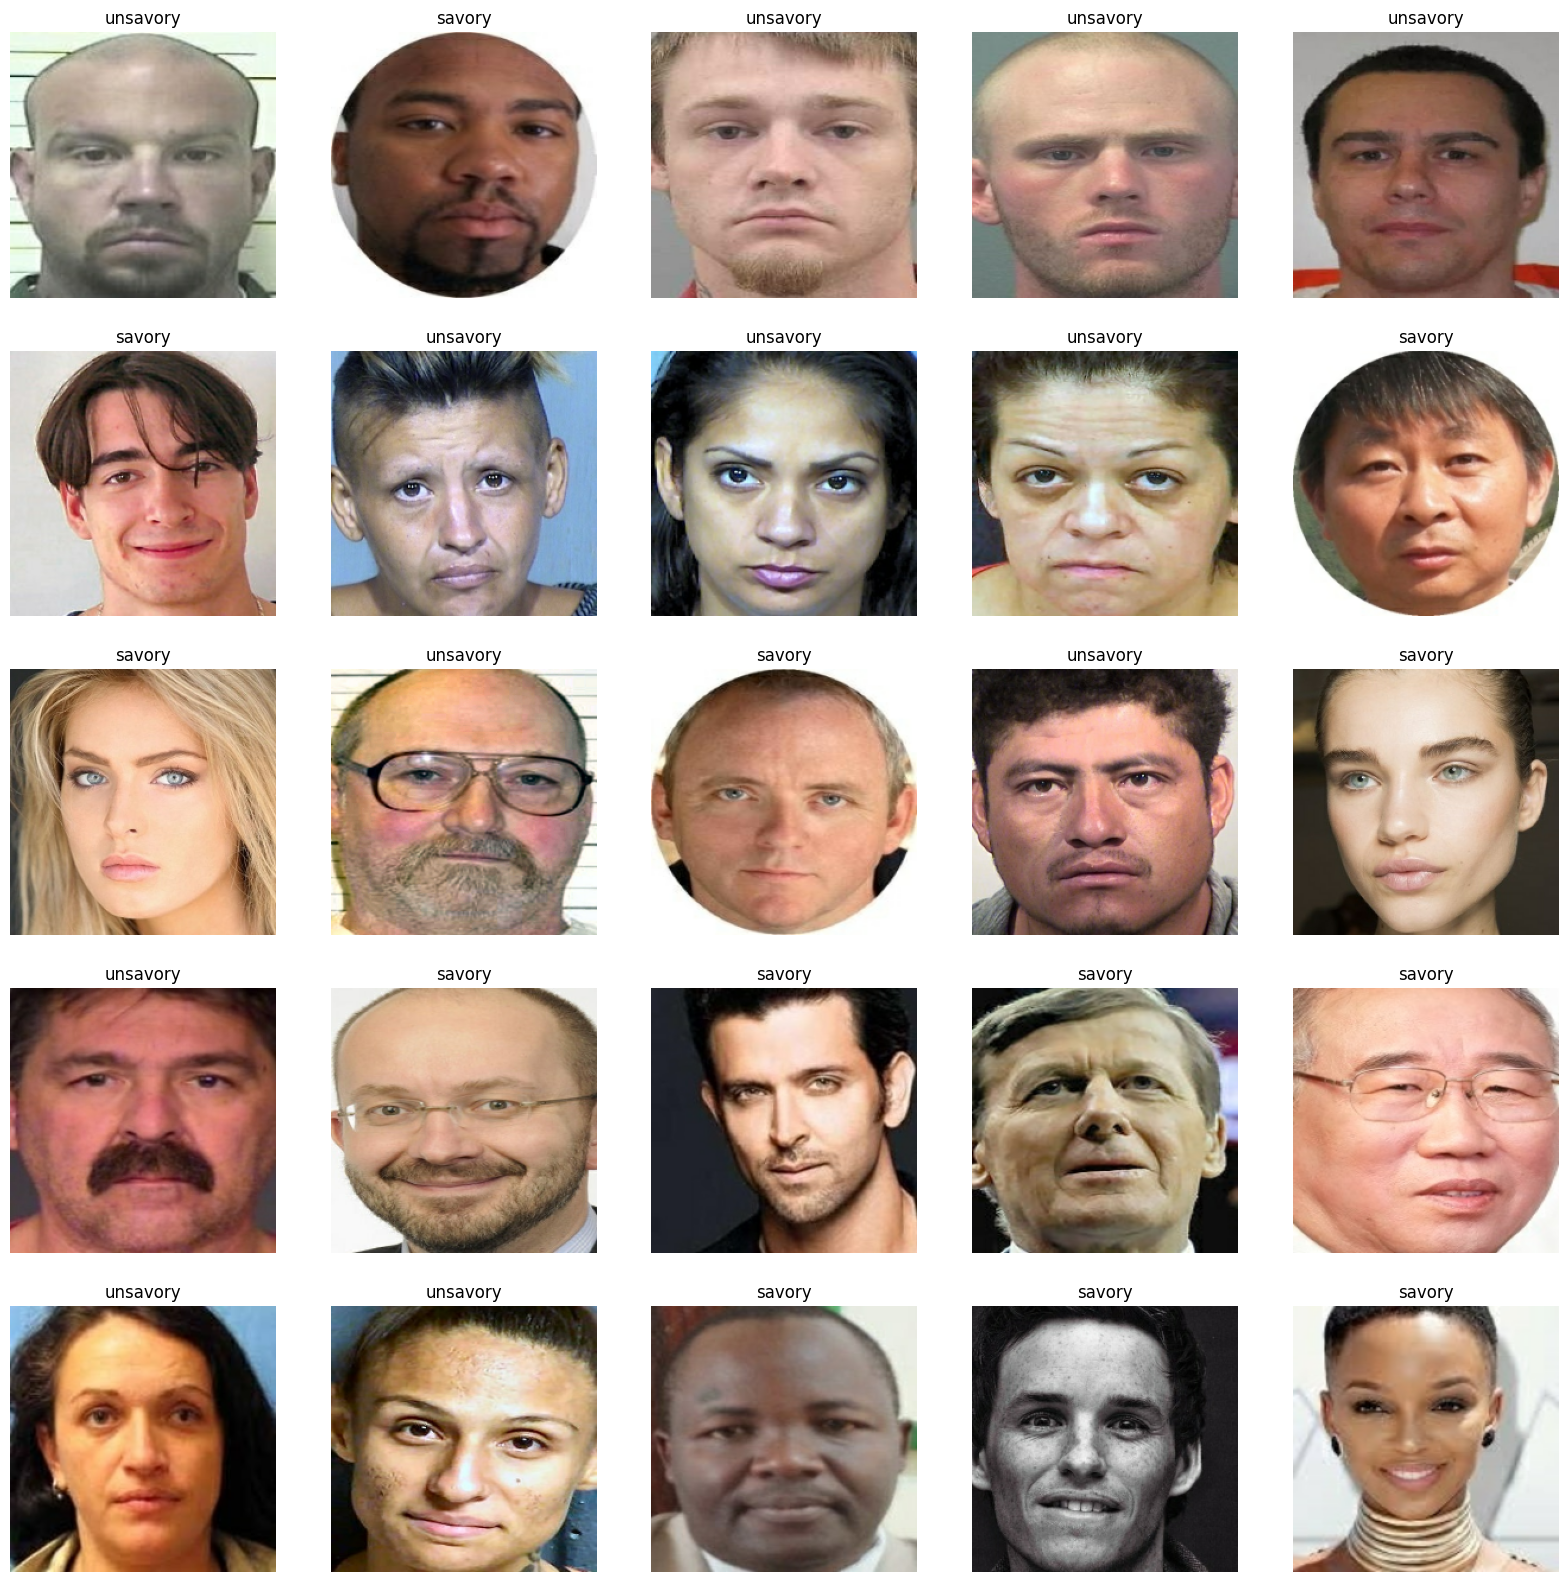

In [12]:
show_images(dataset=train_ds)

In [26]:
def plot_learning_curve(history: pd.DataFrame, test_loss: float=0, test_acc: float=0, test_pre: float=0, test_recall: float=0, test_auc: float=0, title: str=None) -> None:
    """
    Plot the learning curve for a trained model using the history data.

    Args:
        history (pd.DataFrame): DataFrame containing the history data of the model training.
        test_loss (float): The test loss value to use as a reference line in the loss plot.
        test_acc (float): The test accuracy value to use as a reference line in the accuracy plot.
        test_pre (float): The test precision value to use as a reference line in the precision plot.
        test_recall (float): The test recall value to use as a reference line in the recall plot.
        test_auc (float): The test AUC score value to use as a reference line in the AUC plot.
        title (str): Title for the plot.

    Returns:
        None

    Raises:
        TypeError: If history is not a pandas DataFrame.
        ValueError: If the test loss, accuracy, precision, recall, or AUC score are negative.

    """
    
    # Plotting figure config
    plt.figure(figsize=(30,5))
    plt.suptitle(title)

    # Plot the loss
    plt.subplot(1, 5, 1)
    plt.title("Loss Curve")
    plt.plot(history['loss'], label="Loss")
    plt.plot(history['val_loss'], label="VLoss")
    if test_loss:
        plt.axhline(test_loss, color='b', linestyle='--', alpha=0.8)
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.ylim([min(min(history['loss']), min(history['val_loss'])) - 0.05,max(max(history['loss']), max(history['val_loss'])) + 0.05])
    plt.grid()
    
    # Plot the accuracy
    plt.subplot(1, 5, 2)
    plt.title("Accuracy Curve")
    plt.plot(history['accuracy'], label="Acc")
    plt.plot(history['val_accuracy'], label="VAcc")
    if test_acc:
        plt.axhline(test_acc, color='b', linestyle='--', alpha=0.8)
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.ylim([min(min(history['accuracy']), min(history['val_accuracy'])) - 0.05,max(max(history['accuracy']), max(history['val_accuracy'])) + 0.05])
    plt.grid()

    # Plot the precision
    plt.subplot(1, 5, 3)
    plt.title("Precision Curve")
    plt.plot(history['precision'], label="Precision")
    plt.plot(history['val_precision'], label="VPrecision")
    if test_pre:
        plt.axhline(test_pre, color='b', linestyle='--', alpha=0.8)
    plt.xlabel("Epochs")
    plt.ylabel("Precision")
    plt.ylim([min(min(history['precision']), min(history['val_precision'])) - 0.05,max(max(history['precision']), max(history['val_precision'])) + 0.05])
    plt.grid()

    # Plot the recall
    plt.subplot(1, 5, 4)
    plt.title("Recall Curve")
    plt.plot(history['recall'], label="Recall")
    plt.plot(history['val_recall'], label="VRecall")
    if test_recall:
        plt.axhline(test_recall, color='b', linestyle='--', alpha=0.8)
    plt.xlabel("Epochs")
    plt.ylabel("Recall")
    plt.ylim([min(min(history['recall']), min(history['val_recall'])) - 0.05,max(max(history['recall']), max(history['val_recall'])) + 0.05])
    plt.grid()

    # Plot the auc
    plt.subplot(1, 5, 5)
    plt.title("AUC Curve")
    plt.plot(history['auc_score'], label="AUC")
    plt.plot(history['val_auc_score'], label="VAUC")
    if test_auc:
        plt.axhline(test_auc, color='b', linestyle='--', alpha=0.8)
    plt.xlabel("Epochs")
    plt.ylabel("AUC Score")
    plt.ylim([min(min(history['auc_score']), min(history['val_auc_score'])) - 0.01,max(max(history['auc_score']), max(history['val_auc_score'])) + 0.01])
    plt.grid()

    # Show the final plot
    plt.show()

# **Final Model Training**


In [29]:
# Initialize the backbone
backbone = ResNet152V2(include_top=False, weights='./weights/ResNet152v2_Weights.h5', input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
backbone.trainable = False

# Create the model 
best_model = Sequential([
    backbone,
    GlobalAveragePooling2D()
], name="BestResNet152V2")
    
# Make the model architecture
for _ in range(2):
    
    # Add Full Connected Layer
    best_model.add(Dense(128, activation='relu'))
    
    # Use Batch Normalization
    best_model.add(BatchNormalization())
    
    # Drop Out Layer
    best_model.add(Dropout(0.5))
    
# Classification Layer
best_model.add(Dense(1, activation='sigmoid'))
    
# Compile the model
best_model.compile(
    loss = 'binary_crossentropy',
    optimizer = Adam(learning_rate = 1e-3), # best learning rate the 1e-3 are fairly close(same)
    metrics=[
        BinaryAccuracy(name='accuracy'),
        Precision(name='precision'),
        Recall(name='recall'),
        AUC(name='auc_score')
    ]
)
    
# Model summary
best_model.summary()

Model: "BestResNet152V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet152v2 (Functional)        │ ?                      │    58,331,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ ?                      │   0 (unbuilt) │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_780         │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_781         │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,331,648 (222.52 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 58,331,648 (222.52 MB)

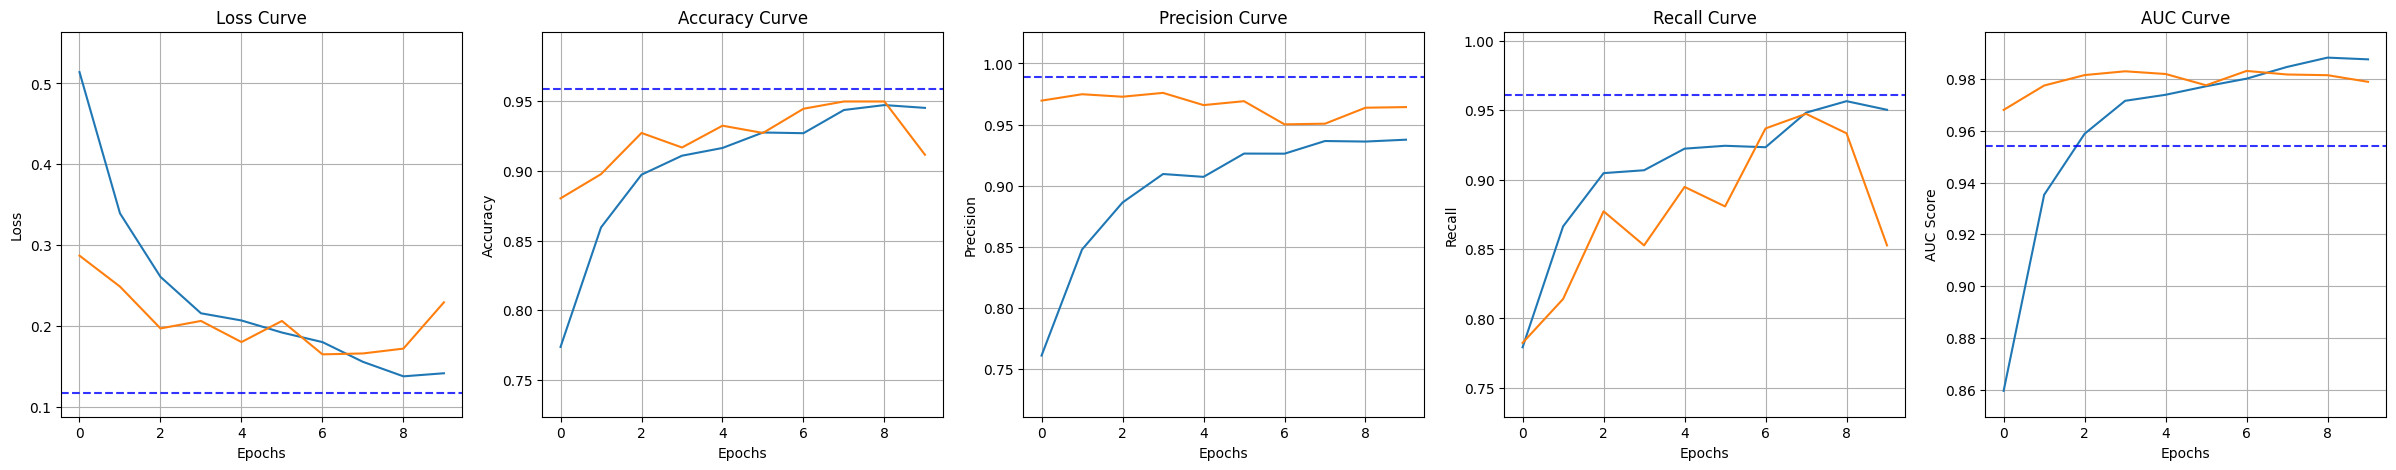

In [31]:
# Best Model Training
best_model_history = best_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=50,
    batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(patience=3, restore_best_weights=True),
        ModelCheckpoint('BestResNet152V2.keras', save_best_only=True)
    ],
    verbose=0
)

# testing performance
test_loss, test_acc, test_pre, test_recall, test_auc = best_model.evaluate(test_ds, verbose=0)

# Obtain the model Learning Curve
history = best_model_history.history

# Plotting figure config
plot_learning_curve(history, test_loss=test_loss, test_acc=test_acc, test_pre=test_pre, test_recall=test_recall, test_auc=test_auc)

While it is **worth noting** that the **performance** of the model can **vary across multiple trainings**, the **learning curve** of the **best model** that I obtained is depicted below.

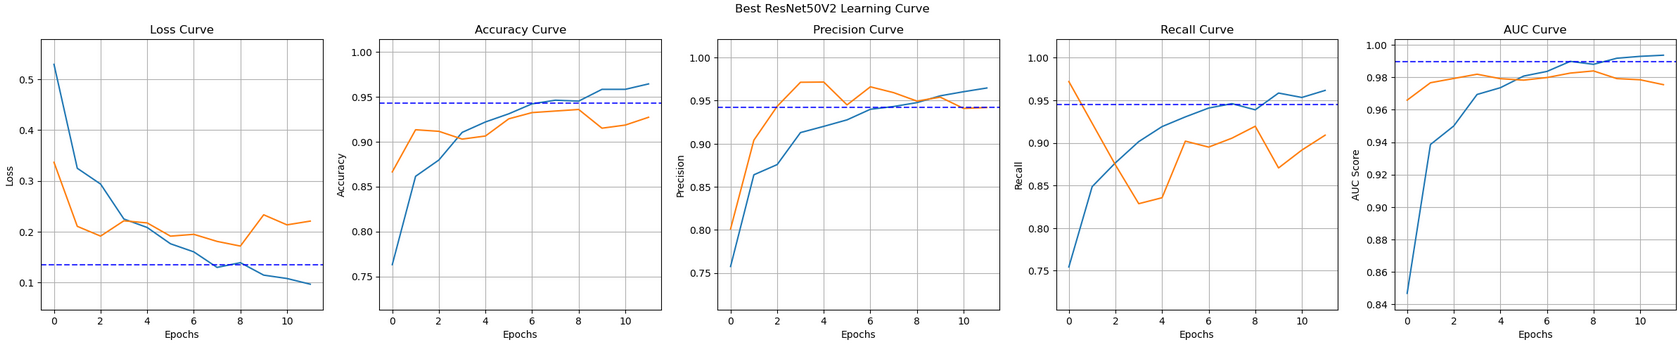

It's **worth mentioning** that **other versions** of the **same model** were also trained, and they were able to **achieve performance** within the **desired range**, with **comparable metrics** to those of **the best model**. However, the **best model** still **stands out** with its **exceptional performance**, and the **additional hypertuning and parameter selection processes** have **undoubtedly contributed to its outstanding performance**.

# **Model Predictions**


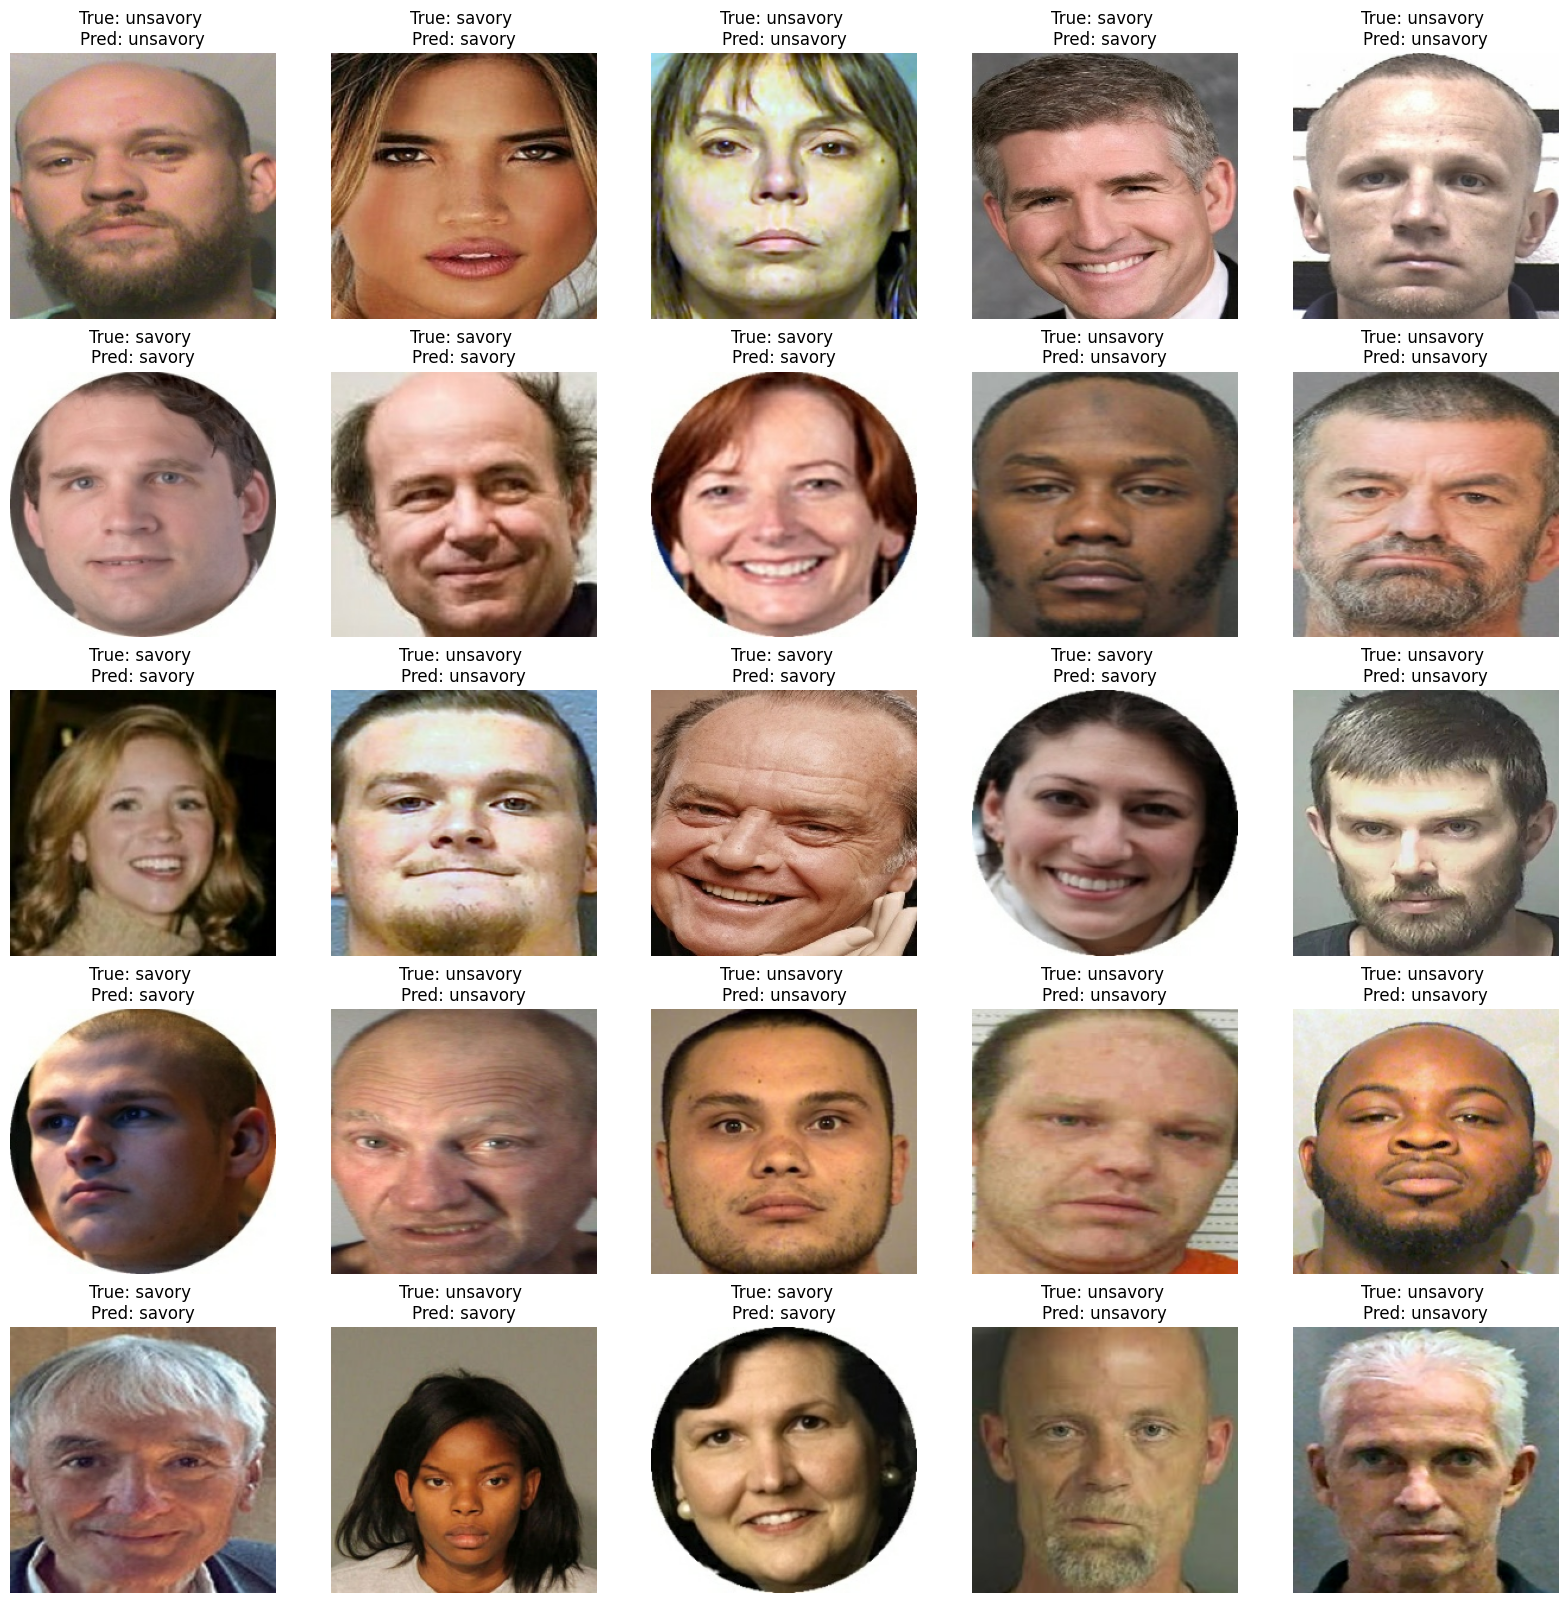

In [32]:
show_images(dataset=test_ds, model=best_model)

In [33]:
# Make model predictions
y_pred = tf.round(best_model.predict(X_test, verbose=0))

In [34]:
# Calculate F1 Score
score = f1_score(Y_test, y_pred)

# Accuracy
acc = accuracy_score(Y_test, y_pred)

# Precision and Recall
pre = precision_score(Y_test, y_pred)
recall = recall_score(Y_test, y_pred)

# ROC AUC Score
roc_auc = recall_score(Y_test, y_pred)

# Complete Classification report
report = classification_report(Y_test, y_pred)

print(f"F1 Score        : {round(score, 4)}")
print(f"Accuracy Score  : {round(acc, 4)}")
print(f"Precision Score : {round(pre, 4)}")
print(f"Recall Score    : {round(recall, 4)}")
print(f"ROC AUC Score   : {round(roc_auc, 4)}")
print(f"\nClassification Report: \n{report}")

F1 Score        : 0.9548
Accuracy Score  : 0.955
Precision Score : 0.9596
Recall Score    : 0.95
ROC AUC Score   : 0.95

Classification Report: 
              precision    recall  f1-score   support

           0       0.95      0.96      0.96       300
           1       0.96      0.95      0.95       300

    accuracy                           0.95       600
   macro avg       0.96      0.95      0.95       600
weighted avg       0.96      0.95      0.95       600

